In [74]:
!pip install silence_tensorflow -q

import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

import tensorflow as tf
from silence_tensorflow import silence_tensorflow
silence_tensorflow("INFO")

from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.applications.efficientnet import preprocess_input


print("TensorFlow:", tf.__version__)


TensorFlow: 2.19.0


In [58]:
base_dir = "/kaggle/input/datasets/kmader/rsna-bone-age"

train_csv_path = os.path.join(base_dir, "boneage-training-dataset.csv")
train_img_dir  = os.path.join(base_dir, "boneage-training-dataset", "boneage-training-dataset")

df = pd.read_csv(train_csv_path)

df["path"] = df["id"].map(lambda x: os.path.join(train_img_dir, f"{x}.png"))
df["gender"] = df["male"].map(lambda x: "male" if x else "female")
df["sex"] = df["gender"].map(lambda x: 1 if x == "male" else 0)

boneage_std = 2 * df["boneage"].std()
boneage_mean = df["boneage"].mean()
df["norm_age"] = (df["boneage"] - boneage_mean) / boneage_std

df.head()


,id,boneage,male,path,gender,sex,norm_age
0,1377,180,False,/kaggle/input/datasets/kmader/rsna-bone-age/bo...,female,0,0.639590
1,1378,12,False,/kaggle/input/datasets/kmader/rsna-bone-age/bo...,female,0,-1.400135
2,1379,94,False,/kaggle/input/datasets/kmader/rsna-bone-age/bo...,female,0,-0.404555
3,1380,120,True,/kaggle/input/datasets/kmader/rsna-bone-age/bo...,male,1,-0.088883
4,1381,82,False,/kaggle/input/datasets/kmader/rsna-bone-age/bo...,female,0,-0.550249


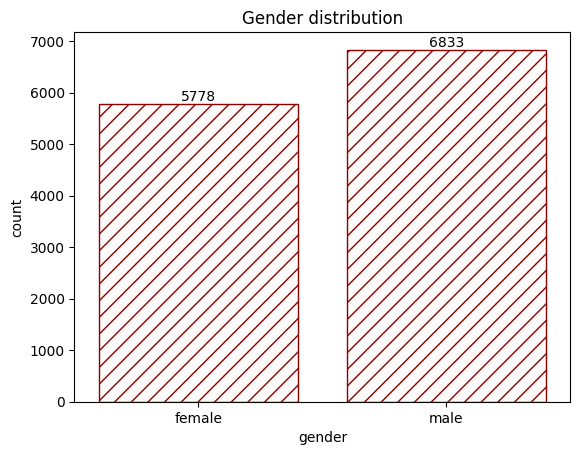

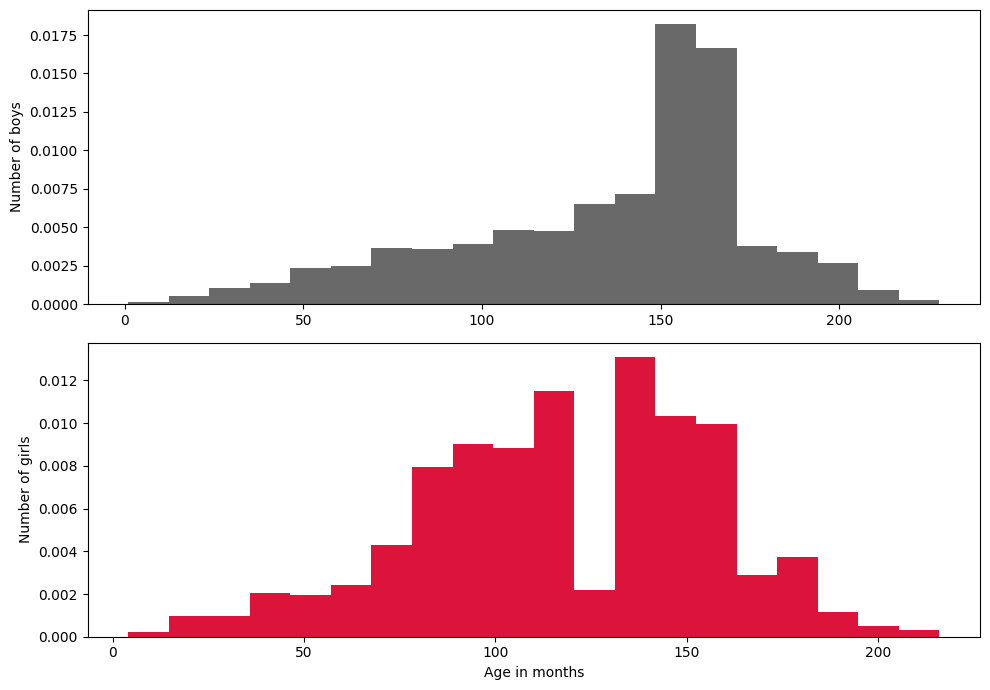

In [59]:
# gender count
ax = sns.countplot(x=df['gender'], color="snow", hatch='//', edgecolor="darkred")
for container in ax.containers:
    ax.bar_label(container)
plt.title("Gender distribution")
plt.show()

# age distribution by gender
male = df[df['gender'] == 'male']
female = df[df['gender'] == 'female']

fig, ax = plt.subplots(2, 1, figsize=(10, 7))
ax[0].hist(male['boneage'], color='dimgray', bins=20, density=True)
ax[0].set_ylabel('Number of boys')
ax[1].hist(female['boneage'], color='crimson', bins=20, density=True)
ax[1].set_xlabel('Age in months')
ax[1].set_ylabel('Number of girls')
plt.tight_layout()
plt.show()


In [60]:
train_df, val_df = train_test_split(df, test_size=0.15, random_state=42)
len(train_df), len(val_df)


(10719, 1892)

In [61]:
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_and_preprocess(image_path, sex, label, training=True):
    img = tf.io.read_file(image_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = preprocess_input(img)

    if training:
        img = tf.image.random_flip_left_right(img)

    sex = tf.cast(sex, tf.float32)
    sex = tf.expand_dims(sex, -1)

    label = tf.cast(label, tf.float32)

    inputs = {
        "image_input": img,
        "gender_input": sex
    }
    return inputs, label

def make_dataset(dataframe, training=True):
    paths = dataframe["path"].values
    sexes = dataframe["sex"].values.astype("float32")
    labels = dataframe["norm_age"].values.astype("float32")

    ds = tf.data.Dataset.from_tensor_slices((paths, sexes, labels))
    if training:
        ds = ds.shuffle(buffer_size=len(dataframe), reshuffle_each_iteration=True)

    ds = ds.map(lambda p, s, y: load_and_preprocess(p, s, y, training=training),
                num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df, training=False)


In [62]:
def build_resnet50_boneage_model():
    img_input = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image_input")
    gender_input = layers.Input(shape=(1,), name="gender_input")

    base_model = ResNet50(
        weights="imagenet",
        include_top=False,
        input_tensor=img_input
    )

    # freeze some early layers for stability
    for layer in base_model.layers[:100]:
        layer.trainable = False

    x = layers.GlobalAveragePooling2D()(base_model.output)

    g = layers.Dense(16, activation="relu")(gender_input)

    combined = layers.Concatenate()([x, g])

    z = layers.Dense(256, activation="relu")(combined)
    z = layers.Dropout(0.4)(z)
    z = layers.Dense(64, activation="relu")(z)
    output = layers.Dense(1, activation="linear", name="boneage_output")(z)

    model = Model(inputs=[img_input, gender_input], outputs=output)

    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss="mae",
        metrics=["mae"]
    )
    return model

model = build_resnet50_boneage_model()
model.summary()


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ image_input[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,132,897 (92.06 MB)

 Trainable params: 19,998,113 (76.29 MB)

 Non-trainable params: 4,134,784 (15.77 MB)

In [63]:
callbacks = [
    EarlyStopping(monitor="val_mae", patience=6, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_mae", factor=0.3, patience=3, verbose=1),
    ModelCheckpoint("best_resnet50_boneage.h5", monitor="val_mae", save_best_only=True, verbose=1)
]

EPOCHS = 30

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)


Epoch 1/30


I0000 00:00:1777212700.758455     268 service.cc:152] XLA service 0x7ceabc001ff0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1777212700.758513     268 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
2026-04-26 14:11:41.597592: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1777212704.847906     268 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-04-26 14:11:46.574556: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:549] Omitted potentially buggy algorithm eng14{} for conv %cudnn-conv-bias-activation.180 = (f32[32,64,56,56]{3,2,1,0}, u8[0]{0}) custom-call(f32[32,64,56,56]{3,2,1,0} %bitcast.25796, f32[64,64,3,3]{3,2,1,0} %bitcast.25803, f32[64]{0} %bitcast.25805), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cu

  1/335 ━━━━━━━━━━━━━━━━━━━━ 3:04:46 33s/step - loss: 0.8484 - mae: 0.8484

I0000 00:00:1777212715.967051     268 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 431ms/step - loss: 0.3549 - mae: 0.3549

...

335/335 ━━━━━━━━━━━━━━━━━━━━ 223s 567ms/step - loss: 0.3544 - mae: 0.3544 - val_loss: 0.2112 - val_mae: 0.2112 - learning_rate: 1.0000e-04
Epoch 2/30
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 335ms/step - loss: 0.1917 - mae: 0.1917
Epoch 2: val_mae improved from 0.21120 to 0.19903, saving model to best_resnet50_boneage.h5


335/335 ━━━━━━━━━━━━━━━━━━━━ 133s 397ms/step - loss: 0.1917 - mae: 0.1917 - val_loss: 0.1990 - val_mae: 0.1990 - learning_rate: 1.0000e-04
Epoch 3/30
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 335ms/step - loss: 0.1717 - mae: 0.1717
Epoch 3: val_mae improved from 0.19903 to 0.19286, saving model to best_resnet50_boneage.h5


335/335 ━━━━━━━━━━━━━━━━━━━━ 133s 396ms/step - loss: 0.1717 - mae: 0.1717 - val_loss: 0.1929 - val_mae: 0.1929 - learning_rate: 1.0000e-04
Epoch 4/30
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 332ms/step - loss: 0.1532 - mae: 0.1532
Epoch 4: val_mae improved from 0.19286 to 0.16527, saving model to best_resnet50_boneage.h5


335/335 ━━━━━━━━━━━━━━━━━━━━ 141s 393ms/step - loss: 0.1532 - mae: 0.1532 - val_loss: 0.1653 - val_mae: 0.1653 - learning_rate: 1.0000e-04
Epoch 5/30
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 331ms/step - loss: 0.1437 - mae: 0.1437
Epoch 5: val_mae improved from 0.16527 to 0.14806, saving model to best_resnet50_boneage.h5


335/335 ━━━━━━━━━━━━━━━━━━━━ 131s 391ms/step - loss: 0.1437 - mae: 0.1437 - val_loss: 0.1481 - val_mae: 0.1481 - learning_rate: 1.0000e-04
Epoch 6/30
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 330ms/step - loss: 0.1289 - mae: 0.1289
Epoch 6: val_mae did not improve from 0.14806
335/335 ━━━━━━━━━━━━━━━━━━━━ 131s 392ms/step - loss: 0.1289 - mae: 0.1289 - val_loss: 0.1565 - val_mae: 0.1565 - learning_rate: 1.0000e-04
Epoch 7/30
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 330ms/step - loss: 0.1255 - mae: 0.1255
Epoch 7: val_mae did not improve from 0.14806
335/335 ━━━━━━━━━━━━━━━━━━━━ 130s 387ms/step - loss: 0.1254 - mae: 0.1254 - val_loss: 0.1937 - val_mae: 0.1937 - learning_rate: 1.0000e-04
Epoch 8/30
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 328ms/step - loss: 0.1163 - mae: 0.1163
Epoch 8: ReduceLROnPlateau reducing learning rate to 2.9999999242136255e-05.

Epoch 8: val_mae did not improve from 0.14806
335/335 ━━━━━━━━━━━━━━━━━━━━ 129s 384ms/step - loss: 0.1163 - mae: 0.1163 - val_loss: 0.1571 - val_mae: 0.1571 - learn

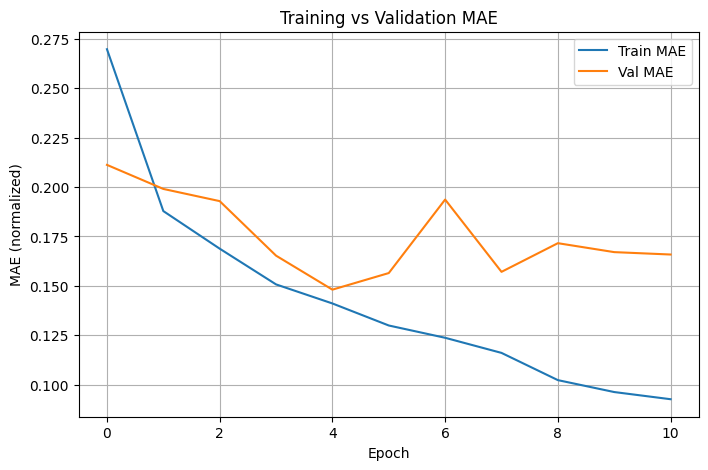

In [64]:
plt.figure(figsize=(8,5))
plt.plot(history.history["mae"], label="Train MAE")
plt.plot(history.history["val_mae"], label="Val MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (normalized)")
plt.title("Training vs Validation MAE")
plt.legend()
plt.grid(True)
plt.show()


In [65]:
def denormalize_age(norm_age):
    return norm_age * boneage_std + boneage_mean

y_true = []
y_pred = []

for batch in val_ds:
    inputs, labels = batch
    preds = model.predict(inputs, verbose=0)
    y_true.extend(labels.numpy().flatten())
    y_pred.extend(preds.flatten())

y_true_months = denormalize_age(np.array(y_true))
y_pred_months = denormalize_age(np.array(y_pred))

val_mae_months = mean_absolute_error(y_true_months, y_pred_months)
print("Validation MAE (months):", val_mae_months)


Validation MAE (months): 12.194970894963273


2026-04-26 14:37:28.089990: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [68]:
# -----------------------------
# CORRECT FINE-TUNING PHASE
# -----------------------------

# 1. Unfreeze only the last 30 layers of ResNet50
for layer in model.layers[-30:]:
    if not isinstance(layer, layers.BatchNormalization):
        layer.trainable = True

print("Unfrozen last 30 layers for fine-tuning.")

# 2. Recompile with a VERY small learning rate
model.compile(
    optimizer=Adam(learning_rate=1e-6),
    loss="mae",
    metrics=["mae"]
)

# 3. Fine-tuning callbacks
fine_tune_callbacks = [
    EarlyStopping(monitor="val_mae", patience=3, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_mae", factor=0.2, patience=2, verbose=1),
    ModelCheckpoint("fine_tuned_resnet50_boneage.h5", monitor="val_mae", save_best_only=True)
]

# 4. Fine-tune for 5–8 epochs
FINE_TUNE_EPOCHS = 8

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=fine_tune_callbacks
)


Unfrozen last 30 layers for fine-tuning.
Epoch 1/8
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 387ms/step - loss: 0.1264 - mae: 0.1264

335/335 ━━━━━━━━━━━━━━━━━━━━ 207s 468ms/step - loss: 0.1264 - mae: 0.1264 - val_loss: 0.1583 - val_mae: 0.1583 - learning_rate: 1.0000e-06
Epoch 2/8
335/335 ━━━━━━━━━━━━━━━━━━━━ 131s 391ms/step - loss: 0.1217 - mae: 0.1217 - val_loss: 0.1669 - val_mae: 0.1669 - learning_rate: 1.0000e-06
Epoch 3/8
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 337ms/step - loss: 0.1252 - mae: 0.1252
Epoch 3: ReduceLROnPlateau reducing learning rate to 1.9999999949504855e-07.
335/335 ━━━━━━━━━━━━━━━━━━━━ 132s 394ms/step - loss: 0.1252 - mae: 0.1252 - val_loss: 0.1627 - val_mae: 0.1627 - learning_rate: 1.0000e-06
Epoch 4/8
335/335 ━━━━━━━━━━━━━━━━━━━━ 132s 392ms/step - loss: 0.1231 - mae: 0.1231 - val_loss: 0.1636 - val_mae: 0.1636 - learning_rate: 2.0000e-07


In [69]:
y_true = []
y_pred = []

for batch in val_ds:
    inputs, labels = batch
    preds = model.predict(inputs, verbose=0)
    y_true.extend(labels.numpy().flatten())
    y_pred.extend(preds.flatten())

y_true_months = denormalize_age(np.array(y_true))
y_pred_months = denormalize_age(np.array(y_pred)) 

val_mae_months = mean_absolute_error(y_true_months, y_pred_months)
print("Fine-tuned Validation MAE (months):", val_mae_months)


Fine-tuned Validation MAE (months): 13.035140054795377


In [70]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def predict_bone_age(image_path, gender_value):
    """
    image_path: full path to the X-ray image
    gender_value: 1 for male, 0 for female
    """

    # Load image
    img = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))

    # Preprocess for model
    img_preprocessed = preprocess_input(img_resized.astype(np.float32))

    # Build input dictionary
    input_tensor = {
        "image_input": np.expand_dims(img_preprocessed, axis=0),
        "gender_input": np.array([[gender_value]], dtype=np.float32)
    }

    # Predict normalized age
    pred_norm = model.predict(input_tensor, verbose=0)[0][0]

    # Convert back to months
    pred_months = denormalize_age(pred_norm)

    # Show image + prediction
    plt.figure(figsize=(6,6))
    plt.imshow(img_rgb)
    plt.title(f"Predicted Bone Age: {pred_months:.2f} months")
    plt.axis("off")
    plt.show()

    return pred_months


2026-04-26 15:44:42.016641: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:549] Omitted potentially buggy algorithm eng14{} for conv %cudnn-conv-bias-activation.162 = (f32[1,64,56,56]{3,2,1,0}, u8[0]{0}) custom-call(f32[1,64,56,56]{3,2,1,0} %bitcast.4594, f32[64,64,3,3]{3,2,1,0} %bitcast.4601, f32[64]{0} %bitcast.4603), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", metadata={op_type="Conv2D" op_name="functional_4_1/conv2_block1_2_conv_1/convolution" source_file="/usr/local/lib/python3.12/dist-packages/tensorflow/python/framework/ops.py" source_line=1200}, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"conv_result_scale":1,"activation_mode":"kNone","side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false}
2026-04-26 15:44:42.121935: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:549] Omitted potent

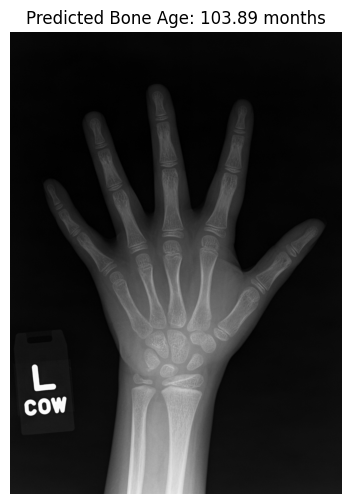

True Age: 94 months
Predicted Age: 103.89 months
Error: 9.89 months


In [71]:
sample_row = val_df.iloc[0]

sample_path = sample_row["path"]
sample_gender = sample_row["sex"]
true_age = sample_row["boneage"]

predicted_age = predict_bone_age(sample_path, sample_gender)

print(f"True Age: {true_age} months")
print(f"Predicted Age: {predicted_age:.2f} months")
print(f"Error: {abs(true_age - predicted_age):.2f} months")


In [77]:
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.applications.efficientnet import preprocess_input

def build_efficientnet_b3_model():
    img_input = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image_input")
    gender_input = layers.Input(shape=(1,), name="gender_input")

    # EfficientNetB3 backbone (correct Keras version)
    base_model = EfficientNetB3(
        weights="imagenet",
        include_top=False,
        input_tensor=img_input
    )

    # Freeze most layers initially
    for layer in base_model.layers[:-30]:
        layer.trainable = False

    # Extract image features
    x = layers.GlobalAveragePooling2D()(base_model.output)

    # Gender branch
    g = layers.Dense(16, activation="relu")(gender_input)

    # Combine image + gender
    combined = layers.Concatenate()([x, g])

    # Regression head
    z = layers.Dense(256, activation="relu")(combined)
    z = layers.Dropout(0.4)(z)
    z = layers.Dense(64, activation="relu")(z)
    output = layers.Dense(1, activation="linear")(z)

    model = Model(inputs=[img_input, gender_input], outputs=output)

    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss="mae",
        metrics=["mae"]
    )

    return model

model = build_efficientnet_b3_model()
model.summary()


43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ image_input[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │      1,080 │ stem_conv_pad[0]… │
│                     │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        160 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        360 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        160 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 40)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 40)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 10)  │        410 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 40)  │        440 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 40)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        960 │ block1a_se_excit

 Total params: 11,197,648 (42.72 MB)

 Trainable params: 3,968,283 (15.14 MB)

 Non-trainable params: 7,229,365 (27.58 MB)

In [78]:
callbacks = [
    EarlyStopping(monitor="val_mae", patience=6, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_mae", factor=0.3, patience=3, verbose=1),
    ModelCheckpoint("efficientnet_b3_base.h5", monitor="val_mae", save_best_only=True)
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=callbacks
)


Epoch 1/25


2026-04-26 15:55:50.175088: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 15:55:50.394080: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 15:55:50.987020: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 15:55:51.251702: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 326ms/step - loss: 0.4215 - mae: 0.4215

2026-04-26 15:58:04.102849: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 15:58:04.322991: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 15:58:04.916414: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 15:58:05.183212: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 399ms/step - loss: 0.4215 - mae: 0.4215

...

335/335 ━━━━━━━━━━━━━━━━━━━━ 129s 385ms/step - loss: 0.3869 - mae: 0.3869 - val_loss: 0.3922 - val_mae: 0.3922 - learning_rate: 1.0000e-04
Epoch 5/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 128s 381ms/step - loss: 0.3827 - mae: 0.3827 - val_loss: 0.3924 - val_mae: 0.3924 - learning_rate: 1.0000e-04
Epoch 6/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 127s 380ms/step - loss: 0.3830 - mae: 0.3830 - val_loss: 0.3946 - val_mae: 0.3946 - learning_rate: 1.0000e-04
Epoch 7/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 325ms/step - loss: 0.3805 - mae: 0.3805

335/335 ━━━━━━━━━━━━━━━━━━━━ 129s 385ms/step - loss: 0.3805 - mae: 0.3805 - val_loss: 0.3888 - val_mae: 0.3888 - learning_rate: 1.0000e-04
Epoch 8/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 128s 381ms/step - loss: 0.3791 - mae: 0.3791 - val_loss: 0.3966 - val_mae: 0.3966 - learning_rate: 1.0000e-04
Epoch 9/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 130s 387ms/step - loss: 0.3809 - mae: 0.3809 - val_loss: 0.3949 - val_mae: 0.3949 - learning_rate: 1.0000e-04
Epoch 10/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 325ms/step - loss: 0.3803 - mae: 0.3803

335/335 ━━━━━━━━━━━━━━━━━━━━ 130s 389ms/step - loss: 0.3803 - mae: 0.3803 - val_loss: 0.3864 - val_mae: 0.3864 - learning_rate: 1.0000e-04
Epoch 11/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 129s 384ms/step - loss: 0.3797 - mae: 0.3797 - val_loss: 0.4000 - val_mae: 0.4000 - learning_rate: 1.0000e-04
Epoch 12/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 128s 382ms/step - loss: 0.3744 - mae: 0.3744 - val_loss: 0.3899 - val_mae: 0.3899 - learning_rate: 1.0000e-04
Epoch 13/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 325ms/step - loss: 0.3734 - mae: 0.3734
Epoch 13: ReduceLROnPlateau reducing learning rate to 2.9999999242136255e-05.
335/335 ━━━━━━━━━━━━━━━━━━━━ 142s 383ms/step - loss: 0.3734 - mae: 0.3734 - val_loss: 0.3894 - val_mae: 0.3894 - learning_rate: 1.0000e-04
Epoch 14/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 128s 382ms/step - loss: 0.3727 - mae: 0.3727 - val_loss: 0.3887 - val_mae: 0.3887 - learning_rate: 3.0000e-05
Epoch 15/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 128s 381ms/step - loss: 0.3644 - mae: 0.3644 - val_loss: 0.3872 - 

335/335 ━━━━━━━━━━━━━━━━━━━━ 129s 384ms/step - loss: 0.3659 - mae: 0.3659 - val_loss: 0.3855 - val_mae: 0.3855 - learning_rate: 3.0000e-05
Epoch 17/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 129s 384ms/step - loss: 0.3723 - mae: 0.3723 - val_loss: 0.3863 - val_mae: 0.3863 - learning_rate: 3.0000e-05
Epoch 18/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 327ms/step - loss: 0.3674 - mae: 0.3674

335/335 ━━━━━━━━━━━━━━━━━━━━ 130s 388ms/step - loss: 0.3674 - mae: 0.3674 - val_loss: 0.3842 - val_mae: 0.3842 - learning_rate: 3.0000e-05
Epoch 19/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 128s 382ms/step - loss: 0.3678 - mae: 0.3678 - val_loss: 0.3869 - val_mae: 0.3869 - learning_rate: 3.0000e-05
Epoch 20/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 128s 381ms/step - loss: 0.3695 - mae: 0.3695 - val_loss: 0.3882 - val_mae: 0.3882 - learning_rate: 3.0000e-05
Epoch 21/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 328ms/step - loss: 0.3631 - mae: 0.3631
Epoch 21: ReduceLROnPlateau reducing learning rate to 8.999999772640877e-06.
335/335 ━━━━━━━━━━━━━━━━━━━━ 129s 386ms/step - loss: 0.3631 - mae: 0.3631 - val_loss: 0.3910 - val_mae: 0.3910 - learning_rate: 3.0000e-05
Epoch 22/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 130s 387ms/step - loss: 0.3667 - mae: 0.3667 - val_loss: 0.3860 - val_mae: 0.3860 - learning_rate: 9.0000e-06
Epoch 23/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 130s 388ms/step - loss: 0.3659 - mae: 0.3659 - val_loss: 0.3874 - v

In [79]:
# Unfreeze top EfficientNet blocks
for layer in model.layers:
    if "block7" in layer.name or "block6" in layer.name:
        layer.trainable = True

# Recompile with smaller LR
model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="mae",
    metrics=["mae"]
)

fine_tune_callbacks = [
    EarlyStopping(monitor="val_mae", patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_mae", factor=0.2, patience=2, verbose=1),
    ModelCheckpoint("efficientnet_b3_finetuned.h5", monitor="val_mae", save_best_only=True)
]

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=fine_tune_callbacks
)


Epoch 1/12


2026-04-26 16:49:14.138988: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 16:49:14.365335: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 16:49:14.590196: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 330ms/step - loss: 0.3859 - mae: 0.3859

2026-04-26 16:51:34.853198: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 16:51:35.077227: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 16:51:35.304615: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 16:51:35.527024: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 420ms/step - loss: 0.3859 - mae: 0.3859

335/335 ━━━━━━━━━━━━━━━━━━━━ 240s 531ms/step - loss: 0.3859 - mae: 0.3859 - val_loss: 0.4305 - val_mae: 0.4305 - learning_rate: 1.0000e-05
Epoch 2/12
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step - loss: 0.3780 - mae: 0.3780

335/335 ━━━━━━━━━━━━━━━━━━━━ 132s 394ms/step - loss: 0.3780 - mae: 0.3780 - val_loss: 0.3906 - val_mae: 0.3906 - learning_rate: 1.0000e-05
Epoch 3/12
335/335 ━━━━━━━━━━━━━━━━━━━━ 131s 390ms/step - loss: 0.3790 - mae: 0.3790 - val_loss: 0.3912 - val_mae: 0.3912 - learning_rate: 1.0000e-05
Epoch 4/12
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 334ms/step - loss: 0.3773 - mae: 0.3773
Epoch 4: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.


335/335 ━━━━━━━━━━━━━━━━━━━━ 133s 396ms/step - loss: 0.3773 - mae: 0.3773 - val_loss: 0.3906 - val_mae: 0.3906 - learning_rate: 1.0000e-05
Epoch 5/12
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 335ms/step - loss: 0.3685 - mae: 0.3685

335/335 ━━━━━━━━━━━━━━━━━━━━ 133s 397ms/step - loss: 0.3685 - mae: 0.3685 - val_loss: 0.3862 - val_mae: 0.3862 - learning_rate: 2.0000e-06
Epoch 6/12
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step - loss: 0.3723 - mae: 0.3723

335/335 ━━━━━━━━━━━━━━━━━━━━ 132s 395ms/step - loss: 0.3723 - mae: 0.3723 - val_loss: 0.3847 - val_mae: 0.3847 - learning_rate: 2.0000e-06
Epoch 7/12
335/335 ━━━━━━━━━━━━━━━━━━━━ 131s 389ms/step - loss: 0.3665 - mae: 0.3665 - val_loss: 0.3873 - val_mae: 0.3873 - learning_rate: 2.0000e-06
Epoch 8/12
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 334ms/step - loss: 0.3654 - mae: 0.3654
Epoch 8: ReduceLROnPlateau reducing learning rate to 3.999999989900971e-07.
335/335 ━━━━━━━━━━━━━━━━━━━━ 131s 392ms/step - loss: 0.3654 - mae: 0.3654 - val_loss: 0.3868 - val_mae: 0.3868 - learning_rate: 2.0000e-06
Epoch 9/12
335/335 ━━━━━━━━━━━━━━━━━━━━ 132s 394ms/step - loss: 0.3659 - mae: 0.3659 - val_loss: 0.3919 - val_mae: 0.3919 - learning_rate: 4.0000e-07
Epoch 10/12
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step - loss: 0.3691 - mae: 0.3691
Epoch 10: ReduceLROnPlateau reducing learning rate to 8.00000009348878e-08.
335/335 ━━━━━━━━━━━━━━━━━━━━ 131s 391ms/step - loss: 0.3691 - mae: 0.3691 - val_loss: 0.3896 - val_mae:

In [80]:
y_true = []
y_pred = []

for batch in val_ds:
    inputs, labels = batch
    preds = model.predict(inputs, verbose=0)
    y_true.extend(labels.numpy().flatten())
    y_pred.extend(preds.flatten())

y_true_months = denormalize_age(np.array(y_true))
y_pred_months = denormalize_age(np.array(y_pred))

val_mae_months = mean_absolute_error(y_true_months, y_pred_months)
print("EfficientNetB3 Fine-tuned Validation MAE (months):", val_mae_months)


EfficientNetB3 Fine-tuned Validation MAE (months): 31.6818027454421


2026-04-26 17:12:58.585407: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [82]:
!pip install silence_tensorflow -q

import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

import tensorflow as tf
from silence_tensorflow import silence_tensorflow
silence_tensorflow("INFO")

from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.applications import EfficientNetV2B0
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
from tensorflow.keras import mixed_precision

print("TensorFlow:", tf.__version__)


TensorFlow: 2.19.0


In [83]:
mixed_precision.set_global_policy("mixed_float16")

IMG_SIZE = 300
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


In [84]:
base_dir = "/kaggle/input/datasets/kmader/rsna-bone-age"

train_csv_path = os.path.join(base_dir, "boneage-training-dataset.csv")
train_img_dir  = os.path.join(base_dir, "boneage-training-dataset", "boneage-training-dataset")

df = pd.read_csv(train_csv_path)

df["path"] = df["id"].map(lambda x: os.path.join(train_img_dir, f"{x}.png"))
df["gender"] = df["male"].map(lambda x: "male" if x else "female")
df["sex"] = df["gender"].map(lambda x: 1 if x == "male" else 0)

boneage_std = 2 * df["boneage"].std()
boneage_mean = df["boneage"].mean()
df["norm_age"] = (df["boneage"] - boneage_mean) / boneage_std

df.head()


,id,boneage,male,path,gender,sex,norm_age
0,1377,180,False,/kaggle/input/datasets/kmader/rsna-bone-age/bo...,female,0,0.639590
1,1378,12,False,/kaggle/input/datasets/kmader/rsna-bone-age/bo...,female,0,-1.400135
2,1379,94,False,/kaggle/input/datasets/kmader/rsna-bone-age/bo...,female,0,-0.404555
3,1380,120,True,/kaggle/input/datasets/kmader/rsna-bone-age/bo...,male,1,-0.088883
4,1381,82,False,/kaggle/input/datasets/kmader/rsna-bone-age/bo...,female,0,-0.550249


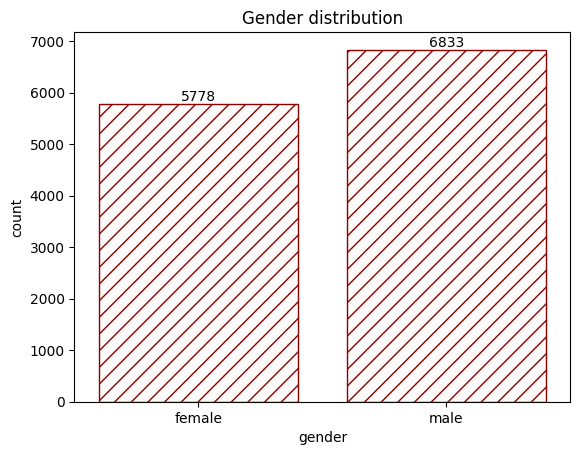

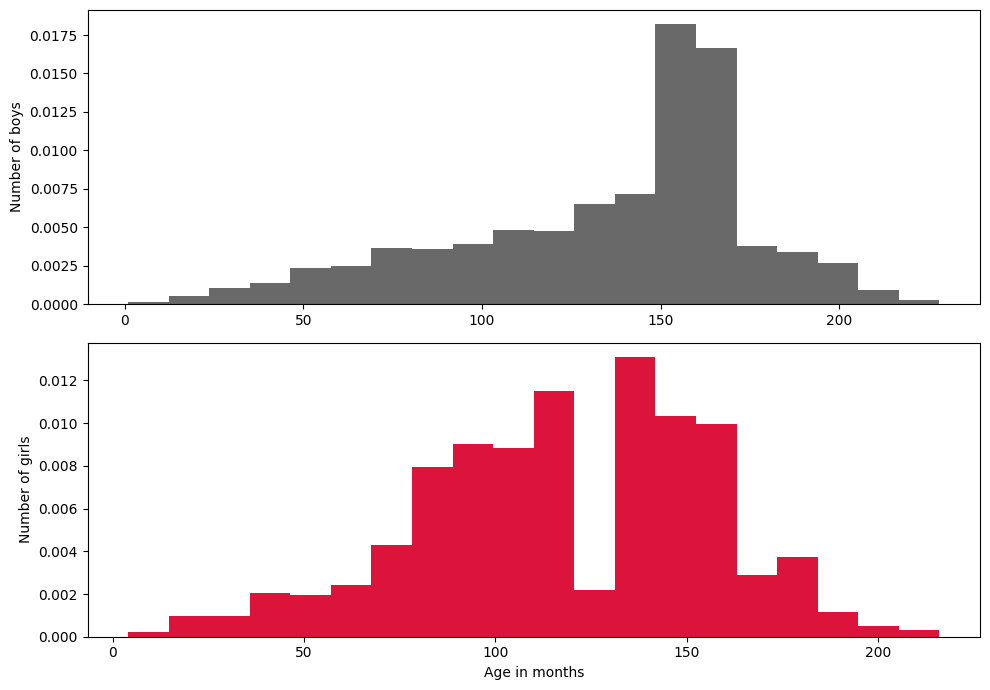

In [85]:
ax = sns.countplot(x=df['gender'], color="snow", hatch='//', edgecolor="darkred")
for container in ax.containers:
    ax.bar_label(container)
plt.title("Gender distribution")
plt.show()

male = df[df['gender'] == 'male']
female = df[df['gender'] == 'female']

fig, ax = plt.subplots(2, 1, figsize=(10, 7))
ax[0].hist(male['boneage'], color='dimgray', bins=20, density=True)
ax[0].set_ylabel('Number of boys')
ax[1].hist(female['boneage'], color='crimson', bins=20, density=True)
ax[1].set_xlabel('Age in months')
ax[1].set_ylabel('Number of girls')
plt.tight_layout()
plt.show()


In [86]:
age_bins = pd.cut(df["boneage"], bins=10)
df["age_bin"] = age_bins

balanced_df = df.groupby("age_bin").apply(
    lambda x: x.sample(min(len(x), 400), replace=True)
).reset_index(drop=True)

balanced_df.drop(columns=["age_bin"], inplace=True)

len(df), len(balanced_df)


(12611, 3400)

In [87]:
train_df, val_df = train_test_split(balanced_df, test_size=0.15, random_state=42)
len(train_df), len(val_df)


(2890, 510)

In [88]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
    layers.RandomBrightness(0.1),
])

def load_and_preprocess(image_path, sex, label, training=True):
    img = tf.io.read_file(image_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = preprocess_input(img)

    if training:
        img = data_augmentation(img)

    sex = tf.cast(sex, tf.float32)
    sex = tf.expand_dims(sex, -1)

    label = tf.cast(label, tf.float32)

    return {"image_input": img, "gender_input": sex}, label

def make_dataset(dataframe, training=True):
    paths = dataframe["path"].values
    sexes = dataframe["sex"].values.astype("float32")
    labels = dataframe["norm_age"].values.astype("float32")

    ds = tf.data.Dataset.from_tensor_slices((paths, sexes, labels))

    if training:
        ds = ds.shuffle(buffer_size=len(dataframe))

    ds = ds.map(
        lambda p, s, y: load_and_preprocess(p, s, y, training=training),
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE).cache().prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df, training=False)


In [89]:
def build_efficientnetv2_model():
    img_input = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image_input")
    gender_input = layers.Input(shape=(1,), name="gender_input")

    base_model = EfficientNetV2B0(
        weights="imagenet",
        include_top=False,
        input_tensor=img_input
    )

    for layer in base_model.layers[:-20]:
        layer.trainable = False

    x = layers.GlobalAveragePooling2D()(base_model.output)

    g = layers.Dense(16, activation="relu")(gender_input)

    combined = layers.Concatenate()([x, g])

    z = layers.Dense(256, activation="relu")(combined)
    z = layers.Dropout(0.4)(z)
    z = layers.Dense(64, activation="relu")(z)
    output = layers.Dense(1, activation="linear", dtype="float32")(z)  # cast back to float32

    model = Model(inputs=[img_input, gender_input], outputs=output)

    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss="mae",
        metrics=["mae"]
    )

    return model

model = build_efficientnetv2_model()
model.summary()


24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_2         │ (None, 300, 300,  │          0 │ image_input[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_1     │ (None, 300, 300,  │          0 │ rescaling_2[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 150, 150,  │        864 │ normalization_1[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 150, 150,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 150, 150,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 150, 150,  │      4,608 │ stem_activation[… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_bn  │ (None, 150, 150,  │         64 │ block1a_project_… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_ac… │ (None, 150, 150,  │          0 │ block1a_project_… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_conv │ (None, 75, 75,    │      9,216 │ block1a_project_… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_bn   │ (None, 75, 75,    │        256 │ block2a_expand_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_act… │ (None, 75, 75,    │          0 │ block2a_expand_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_co… │ (None, 75, 75,    │      2,048 │ block2a_expand_a… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_bn  │ (None, 75, 75,    │        128 │ block2a_project_… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_conv │ (None, 75, 75,    │     36,864 │ block2a_project_… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_bn   │ (None, 75, 75,    │        512 │ block2b_expand_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_act… │ (None, 75, 75,    │          0 │ block2b_expand_b

 Total params: 6,267,889 (23.91 MB)

 Trainable params: 1,166,417 (4.45 MB)

 Non-trainable params: 5,101,472 (19.46 MB)

In [90]:
callbacks = [
    EarlyStopping(monitor="val_mae", patience=6, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_mae", factor=0.3, patience=3, verbose=1),
    ModelCheckpoint("efficientnetv2_base.h5", monitor="val_mae", save_best_only=True)
]

EPOCHS = 25

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)


Epoch 1/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - loss: 0.4978 - mae: 0.4978   

91/91 ━━━━━━━━━━━━━━━━━━━━ 186s 1s/step - loss: 0.4970 - mae: 0.4970 - val_loss: 0.2792 - val_mae: 0.2792 - learning_rate: 1.0000e-04
Epoch 2/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.3084 - mae: 0.3084

91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - loss: 0.3082 - mae: 0.3082 - val_loss: 0.2306 - val_mae: 0.2306 - learning_rate: 1.0000e-04
Epoch 3/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.2661 - mae: 0.2661

91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - loss: 0.2660 - mae: 0.2660 - val_loss: 0.2086 - val_mae: 0.2086 - learning_rate: 1.0000e-04
Epoch 4/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.2447 - mae: 0.2447

91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - loss: 0.2447 - mae: 0.2447 - val_loss: 0.1920 - val_mae: 0.1920 - learning_rate: 1.0000e-04
Epoch 5/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.2281 - mae: 0.2281

...

91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - loss: 0.2032 - mae: 0.2032 - val_loss: 0.1713 - val_mae: 0.1713 - learning_rate: 1.0000e-04
Epoch 8/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.1922 - mae: 0.1922

91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - loss: 0.1923 - mae: 0.1923 - val_loss: 0.1697 - val_mae: 0.1697 - learning_rate: 1.0000e-04
Epoch 9/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - loss: 0.1910 - mae: 0.1910 - val_loss: 0.1732 - val_mae: 0.1732 - learning_rate: 1.0000e-04
Epoch 10/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.1799 - mae: 0.1799

91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - loss: 0.1799 - mae: 0.1799 - val_loss: 0.1636 - val_mae: 0.1636 - learning_rate: 1.0000e-04
Epoch 11/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - loss: 0.1828 - mae: 0.1828 - val_loss: 0.1691 - val_mae: 0.1691 - learning_rate: 1.0000e-04
Epoch 12/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - loss: 0.1746 - mae: 0.1746 - val_loss: 0.1638 - val_mae: 0.1638 - learning_rate: 1.0000e-04
Epoch 13/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.1707 - mae: 0.1707
Epoch 13: ReduceLROnPlateau reducing learning rate to 2.9999999242136255e-05.
91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - loss: 0.1707 - mae: 0.1707 - val_loss: 0.1653 - val_mae: 0.1653 - learning_rate: 1.0000e-04
Epoch 14/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.1671 - mae: 0.1671

91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - loss: 0.1670 - mae: 0.1670 - val_loss: 0.1578 - val_mae: 0.1578 - learning_rate: 3.0000e-05
Epoch 15/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - loss: 0.1604 - mae: 0.1604 - val_loss: 0.1586 - val_mae: 0.1586 - learning_rate: 3.0000e-05
Epoch 16/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - loss: 0.1557 - mae: 0.1557 - val_loss: 0.1602 - val_mae: 0.1602 - learning_rate: 3.0000e-05
Epoch 17/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.1571 - mae: 0.1571

91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - loss: 0.1571 - mae: 0.1571 - val_loss: 0.1539 - val_mae: 0.1539 - learning_rate: 3.0000e-05
Epoch 18/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - loss: 0.1564 - mae: 0.1564 - val_loss: 0.1570 - val_mae: 0.1570 - learning_rate: 3.0000e-05
Epoch 19/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - loss: 0.1510 - mae: 0.1510 - val_loss: 0.1549 - val_mae: 0.1549 - learning_rate: 3.0000e-05
Epoch 20/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.1487 - mae: 0.1487
Epoch 20: ReduceLROnPlateau reducing learning rate to 8.999999772640877e-06.
91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - loss: 0.1488 - mae: 0.1488 - val_loss: 0.1598 - val_mae: 0.1598 - learning_rate: 3.0000e-05
Epoch 21/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - loss: 0.1539 - mae: 0.1539 - val_loss: 0.1542 - val_mae: 0.1542 - learning_rate: 9.0000e-06
Epoch 22/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - loss: 0.1483 - mae: 0.1483 - val_loss: 0.1543 - val_mae: 0.1543 - learning_rate: 9

In [91]:
for layer in model.layers:
    if "block6" in layer.name or "block7" in layer.name:
        layer.trainable = True

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="mae",
    metrics=["mae"]
)

fine_tune_callbacks = [
    EarlyStopping(monitor="val_mae", patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_mae", factor=0.2, patience=2, verbose=1),
    ModelCheckpoint("efficientnetv2_finetuned.h5", monitor="val_mae", save_best_only=True)
]

FINE_TUNE_EPOCHS = 12

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=fine_tune_callbacks
)


Epoch 1/12
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 576ms/step - loss: 0.2435 - mae: 0.2435

91/91 ━━━━━━━━━━━━━━━━━━━━ 151s 858ms/step - loss: 0.2434 - mae: 0.2434 - val_loss: 0.2114 - val_mae: 0.2114 - learning_rate: 1.0000e-05
Epoch 2/12
90/91 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.2219 - mae: 0.2219

91/91 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - loss: 0.2218 - mae: 0.2218 - val_loss: 0.2086 - val_mae: 0.2086 - learning_rate: 1.0000e-05
Epoch 3/12
91/91 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - loss: 0.1996 - mae: 0.1996 - val_loss: 0.2096 - val_mae: 0.2096 - learning_rate: 1.0000e-05
Epoch 4/12
90/91 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.1929 - mae: 0.1929

91/91 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - loss: 0.1930 - mae: 0.1930 - val_loss: 0.2014 - val_mae: 0.2014 - learning_rate: 1.0000e-05
Epoch 5/12
90/91 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 0.1848 - mae: 0.1848

91/91 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - loss: 0.1849 - mae: 0.1849 - val_loss: 0.2014 - val_mae: 0.2014 - learning_rate: 1.0000e-05
Epoch 6/12
90/91 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.1841 - mae: 0.1841

91/91 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - loss: 0.1842 - mae: 0.1842 - val_loss: 0.1922 - val_mae: 0.1922 - learning_rate: 1.0000e-05
Epoch 7/12
90/91 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.1769 - mae: 0.1769

91/91 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - loss: 0.1769 - mae: 0.1769 - val_loss: 0.1888 - val_mae: 0.1888 - learning_rate: 1.0000e-05
Epoch 8/12
91/91 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - loss: 0.1707 - mae: 0.1707 - val_loss: 0.1933 - val_mae: 0.1933 - learning_rate: 1.0000e-05
Epoch 9/12
90/91 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.1686 - mae: 0.1686
Epoch 9: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
91/91 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - loss: 0.1686 - mae: 0.1686 - val_loss: 0.1888 - val_mae: 0.1888 - learning_rate: 1.0000e-05
Epoch 10/12
90/91 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.1702 - mae: 0.1702

91/91 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - loss: 0.1702 - mae: 0.1702 - val_loss: 0.1856 - val_mae: 0.1856 - learning_rate: 2.0000e-06
Epoch 11/12
90/91 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.1682 - mae: 0.1682

91/91 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - loss: 0.1682 - mae: 0.1682 - val_loss: 0.1855 - val_mae: 0.1855 - learning_rate: 2.0000e-06
Epoch 12/12
90/91 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.1668 - mae: 0.1668

91/91 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step - loss: 0.1669 - mae: 0.1669 - val_loss: 0.1849 - val_mae: 0.1849 - learning_rate: 2.0000e-06


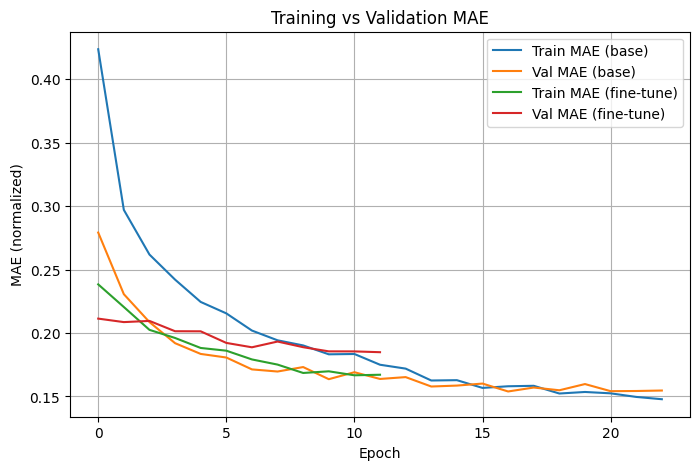

In [92]:
plt.figure(figsize=(8,5))
plt.plot(history.history["mae"], label="Train MAE (base)")
plt.plot(history.history["val_mae"], label="Val MAE (base)")
if "mae" in history_finetune.history:
    plt.plot(history_finetune.history["mae"], label="Train MAE (fine-tune)")
    plt.plot(history_finetune.history["val_mae"], label="Val MAE (fine-tune)")
plt.xlabel("Epoch")
plt.ylabel("MAE (normalized)")
plt.title("Training vs Validation MAE")
plt.legend()
plt.grid(True)
plt.show()


In [93]:
def denormalize_age(norm_age):
    return norm_age * boneage_std + boneage_mean

y_true = []
y_pred = []

for batch in val_ds:
    inputs, labels = batch
    preds = model.predict(inputs, verbose=0)
    y_true.extend(labels.numpy().flatten())
    y_pred.extend(preds.flatten())

y_true_months = denormalize_age(np.array(y_true))
y_pred_months = denormalize_age(np.array(y_pred))

val_mae_months = mean_absolute_error(y_true_months, y_pred_months)
print("EfficientNetV2 Fine-tuned Validation MAE (months):", val_mae_months)


EfficientNetV2 Fine-tuned Validation MAE (months): 15.228929384381455


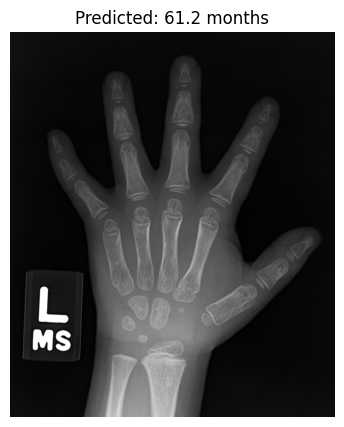

True Age: 33 months
Predicted Age: 61.23 months
Error: 28.23 months


In [94]:
import cv2

def predict_bone_age(image_path, gender_value):
    img = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
    img_preprocessed = preprocess_input(img_resized.astype(np.float32))

    input_tensor = {
        "image_input": np.expand_dims(img_preprocessed, axis=0),
        "gender_input": np.array([[gender_value]], dtype=np.float32)
    }

    pred_norm = model.predict(input_tensor, verbose=0)[0][0]
    pred_months = denormalize_age(pred_norm)

    plt.figure(figsize=(5,5))
    plt.imshow(img_rgb)
    plt.title(f"Predicted: {pred_months:.1f} months")
    plt.axis("off")
    plt.show()

    return pred_months

sample_row = val_df.iloc[0]
sample_path = sample_row["path"]
sample_gender = sample_row["sex"]
true_age = sample_row["boneage"]

predicted_age = predict_bone_age(sample_path, sample_gender)

print(f"True Age: {true_age} months")
print(f"Predicted Age: {predicted_age:.2f} months")
print(f"Error: {abs(true_age - predicted_age):.2f} months")
